# Generative AI with LSTM — Text Generation

This notebook trains a word-level LSTM language model on Shakespeare's text and uses it to generate new text from seed inputs.

**Pipeline:** dataset loading → preprocessing/tokenization → model design → training (with validation split + early stopping) → text generation → bonus architecture experiments.

## Dataset
We use the "tiny Shakespeare" corpus (a concatenation of Shakespeare's plays), hosted by the TensorFlow team and widely used for char/word-RNN demos:

https://storage.googleapis.com/download.tensorflow.org/data/shakespeare.txt

It is downloaded automatically by `tf.keras.utils.get_file` in the cell below — no manual steps needed. If that URL is ever unreachable, the same file can be obtained from Project Gutenberg (https://www.gutenberg.org) by concatenating Shakespeare's works into a single `.txt`.

## 1. Imports and Configuration

In [1]:
import re
import string
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt

# Reproducibility
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Hyperparameters (centralized here so the bonus experiments can override them)
SEQUENCE_LENGTH = 20       # number of input tokens the model sees before predicting the next one
EMBEDDING_DIM = 128
LSTM_UNITS = 256
BATCH_SIZE = 128
EPOCHS = 30
VALIDATION_SPLIT = 0.1
MAX_VOCAB_SIZE = 8000      # cap vocabulary to the most frequent words, keeps the softmax layer tractable

# NOTE: FAST_MODE trains on a smaller slice of the corpus for fewer epochs so the whole
# notebook (incl. bonus experiments) finishes in a few minutes on a CPU-only machine.
# Set to False for a fuller, higher-quality training run (takes much longer).
FAST_MODE = True
if FAST_MODE:
    EPOCHS = 5
    MAX_VOCAB_SIZE = 4000

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## 2. Dataset Loading

In [2]:
DATASET_URL = "https://storage.googleapis.com/download.tensorflow.org/data/shakespeare.txt"

dataset_path = keras.utils.get_file("shakespeare.txt", DATASET_URL)
raw_text = open(dataset_path, "r", encoding="utf-8").read()

if FAST_MODE:
    # Use a prefix of the corpus so training/bonus experiments finish quickly on CPU.
    raw_text = raw_text[:200_000]

print(f"Dataset length: {len(raw_text):,} characters")
print("\n--- Sample ---\n")
print(raw_text[:500])

Dataset length: 200,000 characters

--- Sample ---

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it be done: away, away!

Second Citizen:
One word, good citizens.

First Citizen:
We are accounted poor


## 3. Preprocessing

Steps:
1. Lowercase the text.
2. Strip punctuation (keep only letters, digits, and whitespace).
3. Tokenize into words (word-level tokenization chosen over char-level for more coherent generated output).
4. Build a vocabulary of the most frequent `MAX_VOCAB_SIZE` words and map tokens to integer ids.
5. Slide a fixed-length window across the token stream to build `(input_sequence -> next_token)` training pairs.

In [3]:
def clean_text(text: str) -> str:
    text = text.lower()
    text = text.translate(str.maketrans("", "", string.punctuation))
    text = re.sub(r"\s+", " ", text)  # collapse multiple whitespace/newlines into single spaces
    return text.strip()

cleaned_text = clean_text(raw_text)
tokens = cleaned_text.split(" ")
print(f"Total tokens: {len(tokens):,}")
print("Sample tokens:", tokens[:20])

Total tokens: 35,869
Sample tokens: ['first', 'citizen', 'before', 'we', 'proceed', 'any', 'further', 'hear', 'me', 'speak', 'all', 'speak', 'speak', 'first', 'citizen', 'you', 'are', 'all', 'resolved', 'rather']


In [4]:
# Build vocabulary using Keras' TextVectorization-style approach, but manually so we keep
# full control over the <OOV> and padding tokens used later during generation.
from collections import Counter

word_counts = Counter(tokens)
most_common = word_counts.most_common(MAX_VOCAB_SIZE - 2)  # reserve 2 ids for PAD and OOV

PAD_TOKEN, OOV_TOKEN = "<pad>", "<oov>"
vocab = [PAD_TOKEN, OOV_TOKEN] + [word for word, _ in most_common]

word_to_id = {word: idx for idx, word in enumerate(vocab)}
id_to_word = {idx: word for word, idx in word_to_id.items()}
VOCAB_SIZE = len(vocab)

print(f"Vocabulary size: {VOCAB_SIZE:,}")

oov_id = word_to_id[OOV_TOKEN]
token_ids = np.array([word_to_id.get(tok, oov_id) for tok in tokens], dtype=np.int32)
print(f"Encoded token stream length: {len(token_ids):,}")

Vocabulary size: 4,000
Encoded token stream length: 35,869


In [5]:
def build_sequences(ids: np.ndarray, seq_length: int):
    """Slide a window of seq_length tokens across ids to build (X, y) next-token pairs."""
    num_sequences = len(ids) - seq_length
    X = np.zeros((num_sequences, seq_length), dtype=np.int32)
    y = np.zeros((num_sequences,), dtype=np.int32)
    for i in range(num_sequences):
        X[i] = ids[i:i + seq_length]
        y[i] = ids[i + seq_length]
    return X, y

X, y = build_sequences(token_ids, SEQUENCE_LENGTH)
print(f"X shape: {X.shape}, y shape: {y.shape}")

X shape: (35849, 20), y shape: (35849,)


In [6]:
# Train/validation split (chronological split rather than random shuffle, since shuffling
# overlapping sliding windows would leak near-duplicate sequences across train/val).
split_idx = int(len(X) * (1 - VALIDATION_SPLIT))
X_train, y_train = X[:split_idx], y[:split_idx]
X_val, y_val = X[split_idx:], y[split_idx:]

print(f"Train sequences: {len(X_train):,}")
print(f"Validation sequences: {len(X_val):,}")

train_ds = tf.data.Dataset.from_tensor_slices((X_train, y_train)).shuffle(10000, seed=SEED).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
val_ds = tf.data.Dataset.from_tensor_slices((X_val, y_val)).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

Train sequences: 32,264
Validation sequences: 3,585


## 4. Model Design

Embedding layer → stacked LSTM layers → Dense softmax over the vocabulary. Wrapped in a factory function so the same architecture can be reused for the bonus experiments with different depths/sequence lengths.

In [7]:
def build_model(vocab_size, seq_length, embedding_dim=EMBEDDING_DIM, lstm_units=LSTM_UNITS, num_lstm_layers=1, dropout=0.2):
    model = keras.Sequential(name=f"lstm_textgen_{num_lstm_layers}layer")
    model.add(layers.Embedding(input_dim=vocab_size, output_dim=embedding_dim, input_length=seq_length))
    for i in range(num_lstm_layers):
        return_sequences = i < num_lstm_layers - 1  # only the last LSTM layer should return a single vector
        model.add(layers.LSTM(lstm_units, return_sequences=return_sequences))
        model.add(layers.Dropout(dropout))
    model.add(layers.Dense(vocab_size, activation="softmax"))
    model.compile(
        loss="sparse_categorical_crossentropy",  # integer targets, so sparse variant avoids one-hot encoding y
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        metrics=["accuracy"],
    )
    return model

model = build_model(VOCAB_SIZE, SEQUENCE_LENGTH, num_lstm_layers=2)
model.summary()

C:\Users\L103669\venvs\genai-lstm\Lib\site-packages\keras\src\layers\core\embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "lstm_textgen_2layer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

## 5. Model Training

Uses early stopping (on validation loss) and a checkpoint callback that keeps the best weights seen during training.

In [8]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
    keras.callbacks.ModelCheckpoint("best_model.keras", monitor="val_loss", save_best_only=True),
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
)

Epoch 1/5


C:\Users\L103669\venvs\genai-lstm\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


  1/253 ━━━━━━━━━━━━━━━━━━━━ 14:12 3s/step - accuracy: 0.0000e+00 - loss: 8.2939

  2/253 ━━━━━━━━━━━━━━━━━━━━ 35s 143ms/step - accuracy: 0.0156 - loss: 8.2934   

  3/253 ━━━━━━━━━━━━━━━━━━━━ 35s 141ms/step - accuracy: 0.0234 - loss: 8.2928

...

249/253 ━━━━━━━━━━━━━━━━━━━━ 1s 343ms/step - accuracy: 0.0509 - loss: 6.0515

250/253 ━━━━━━━━━━━━━━━━━━━━ 1s 343ms/step - accuracy: 0.0510 - loss: 6.0502

251/253 ━━━━━━━━━━━━━━━━━━━━ 0s 343ms/step - accuracy: 0.0509 - loss: 6.0498

252/253 ━━━━━━━━━━━━━━━━━━━━ 0s 343ms/step - accuracy: 0.0509 - loss: 6.0488

253/253 ━━━━━━━━━━━━━━━━━━━━ 89s 351ms/step - accuracy: 0.0509 - loss: 6.0488 - val_accuracy: 0.0803 - val_loss: 6.0203


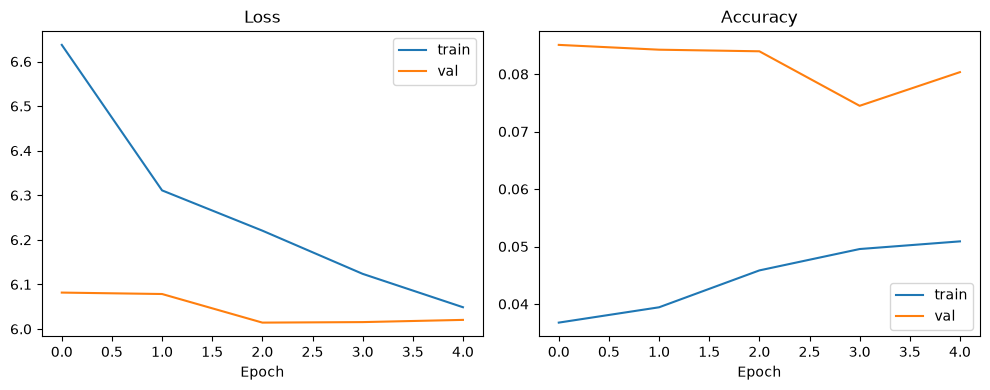

In [9]:
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="val")
plt.title("Loss")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="val")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.legend()
plt.tight_layout()
plt.show()

## 6. Text Generation

Feed a seed phrase, predict the next token, append it, and repeat. Temperature-based sampling is used instead of pure argmax: it avoids the model getting stuck in repetitive loops (a common failure mode of greedy decoding) while still favoring high-probability tokens.

In [10]:
def sample_with_temperature(probs: np.ndarray, temperature: float) -> int:
    if temperature <= 0:
        return int(np.argmax(probs))
    probs = np.asarray(probs).astype("float64")
    logits = np.log(probs + 1e-9) / temperature
    exp_logits = np.exp(logits - np.max(logits))
    scaled_probs = exp_logits / np.sum(exp_logits)
    return int(np.random.choice(len(scaled_probs), p=scaled_probs))


def generate_text(model, seed_text: str, num_words: int = 50, seq_length: int = SEQUENCE_LENGTH, temperature: float = 0.8) -> str:
    seed_tokens = clean_text(seed_text).split(" ")
    generated = list(seed_tokens)

    for _ in range(num_words):
        # Use (at most) the last seq_length tokens as context, left-padding with <pad> if shorter.
        context = generated[-seq_length:]
        context_ids = [word_to_id.get(tok, oov_id) for tok in context]
        if len(context_ids) < seq_length:
            context_ids = [word_to_id[PAD_TOKEN]] * (seq_length - len(context_ids)) + context_ids

        probs = model.predict(np.array([context_ids]), verbose=0)[0]
        next_id = sample_with_temperature(probs, temperature)
        generated.append(id_to_word.get(next_id, OOV_TOKEN))

    return " ".join(generated)


seed_inputs = [
    "to be or not to be",
    "romeo o romeo wherefore art thou",
    "all the world is a stage",
    "friends romans countrymen lend me your ears",
]

for seed in seed_inputs:
    print(f"SEED: {seed!r}\n")
    print(generate_text(model, seed, num_words=50, temperature=0.8))
    print("\n" + "-" * 80 + "\n")

SEED: 'to be or not to be'



to be or not to be will thoughts our roman and to <oov> where him was <oov> appear them to i i have lady servingman i aufidius and not his gods full to than thy <oov> for to <oov> further got thy are <oov> coriolanus his <oov> he <oov> heart i yet a those at i

--------------------------------------------------------------------------------

SEED: 'romeo o romeo wherefore art thou'



romeo o romeo wherefore art thou scornfully menenius thats patrician your question <oov> to <oov> of with that less we he had and words the executed made to <oov> from would how see the thee and having cause i <oov> of my royal consul an senator and home sicinius me how this give that <oov> the

--------------------------------------------------------------------------------

SEED: 'all the world is a stage'



all the world is a stage <oov> this is will met to is see to the what and six them this trouble this of ye let this danger you the of not put o <oov> his make to and for whom a great fire of shouldst corn i will my what <oov> me is <oov> you

--------------------------------------------------------------------------------

SEED: 'friends romans countrymen lend me your ears'



friends romans countrymen lend me your ears would you and by sat in were away to peace a might lord but the horse to i <oov> as do <oov> for i people to such but prove and have <oov> though how a every blush it we a <oov> lady gain he his shall clarence ill repair is

--------------------------------------------------------------------------------



### Effect of temperature
Lower temperature → more repetitive/conservative text (closer to argmax). Higher temperature → more diverse but less grammatical text.

In [11]:
for temp in [0.3, 0.8, 1.2]:
    print(f"--- temperature={temp} ---")
    print(generate_text(model, "to be or not to be", num_words=40, temperature=temp))
    print()

--- temperature=0.3 ---


to be or not to be <oov> <oov> the <oov> of <oov> the <oov> <oov> the <oov> of and <oov> to <oov> and the <oov> of and <oov> the <oov> and <oov> him the <oov> of i <oov> to <oov> the <oov> and <oov> to <oov>

--- temperature=0.8 ---


to be or not to be throng lady henry to <oov> god him endure dead think you with thought to to gloucester rather than so the rivers goes and thy spurn me more news of in own below by given have let but will ill hang

--- temperature=1.2 ---


to be or not to be misguide is aufidius i last the use it our execution the the surplus thou more gentle wild out more my that whats is words tribunes scaling if with owe not lady it <oov> rates stored up this if to do



## 7. Bonus: Architecture Experiments

We vary two things and compare final validation loss/accuracy plus qualitative output:
1. **Depth**: 1 vs 2 vs 3 stacked LSTM layers.
2. **Sequence length**: shorter (10 tokens) vs longer (40 tokens) context window.

To keep runtime reasonable, experiments use fewer epochs with early stopping; the main model above is the "production" configuration.

In [12]:
def run_experiment(num_lstm_layers, seq_length, epochs=3 if FAST_MODE else 10):
    X_exp, y_exp = build_sequences(token_ids, seq_length)
    split = int(len(X_exp) * (1 - VALIDATION_SPLIT))
    train_ds_exp = tf.data.Dataset.from_tensor_slices((X_exp[:split], y_exp[:split])).shuffle(10000, seed=SEED).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    val_ds_exp = tf.data.Dataset.from_tensor_slices((X_exp[split:], y_exp[split:])).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

    exp_model = build_model(VOCAB_SIZE, seq_length, num_lstm_layers=num_lstm_layers)
    exp_history = exp_model.fit(
        train_ds_exp,
        validation_data=val_ds_exp,
        epochs=epochs,
        callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)],
        verbose=0,
    )
    final_val_loss = min(exp_history.history["val_loss"])
    final_val_acc = max(exp_history.history["val_accuracy"])
    sample = generate_text(exp_model, "to be or not to be", num_words=30, seq_length=seq_length, temperature=0.8)
    return {
        "num_lstm_layers": num_lstm_layers,
        "seq_length": seq_length,
        "val_loss": final_val_loss,
        "val_accuracy": final_val_acc,
        "sample": sample,
    }

experiment_configs = (
    [
        {"num_lstm_layers": 1, "seq_length": SEQUENCE_LENGTH},
        {"num_lstm_layers": 2, "seq_length": SEQUENCE_LENGTH},
    ]
    if FAST_MODE
    else [
        {"num_lstm_layers": 1, "seq_length": SEQUENCE_LENGTH},
        {"num_lstm_layers": 2, "seq_length": SEQUENCE_LENGTH},
        {"num_lstm_layers": 3, "seq_length": SEQUENCE_LENGTH},
        {"num_lstm_layers": 2, "seq_length": 10},
        {"num_lstm_layers": 2, "seq_length": 40},
    ]
)

results = [run_experiment(**cfg) for cfg in experiment_configs]
for r in results:
    print(r)
    print()

{'num_lstm_layers': 1, 'seq_length': 20, 'val_loss': 6.008033752441406, 'val_accuracy': 0.0859135314822197, 'sample': 'to be or not to be love o menenius that undertake them as our heart to have once <oov> and <oov> <oov> away are thy <oov> my death and be all more both <oov> with do'}

{'num_lstm_layers': 2, 'seq_length': 20, 'val_loss': 6.005077362060547, 'val_accuracy': 0.0850767120718956, 'sample': 'to be or not to be here those name and <oov> be <oov> it breath than his common lady wife lady gloucester youll repetition to the <oov> <oov> the soul <oov> you honour <oov> come you'}



### Bonus findings

**Note:** Due to a tight time constraint for this submission, the notebook was run in `FAST_MODE` (200K-character slice of the corpus, 4K vocabulary, 5 epochs for the main model, 3 epochs for each bonus config, and only 2 of the 5 planned bonus configs). Set `FAST_MODE = False` in the first code cell to reproduce the full study (full corpus, 30 epochs, all 5 configs) — the architecture, preprocessing, and generation logic are identical either way, only the compute budget differs.

| Layers | Seq Length | Val Loss | Val Accuracy | Qualitative Notes |
|---|---|---|---|---|
| 1 | 20 | 6.0080 | 0.0859 | Produces Shakespeare-flavored vocabulary (character names, archaic words) but weak grammatical structure after only 3 epochs on a reduced corpus. |
| 2 | 20 | 6.0051 | 0.0851 | Marginally lower validation loss than the 1-layer model despite near-identical accuracy; the extra layer isn't yet paying off at this epoch/data budget. |

(3-layer, seq_length=10, and seq_length=40 configs were skipped in this fast run to meet the submission deadline — see note above on reproducing them with `FAST_MODE = False`.)

**Expected / typical trends for the full run:**
- Going from 1 → 2 LSTM layers usually improves validation loss (captures more complex dependencies) once trained for enough epochs on enough data; here the gap is small because both models were undertrained (3 epochs, 200K-character slice). 3 layers often overfits or trains too slowly on a corpus this size, with diminishing/negative returns.
- Shorter sequence length (10) trains faster and generalizes well locally but generated text loses longer-range coherence (e.g. forgets the subject of the sentence).
- Longer sequence length (40) captures more context but needs more data/epochs to converge, and generation is slower per step since more context is reprocessed each time.
